# 23 · MCP discovery: a client finds what a server offers
Level L4 · Part 4 · core · ~25 min · builds on 22

## Goal
A client that connects to an MCP server does not need a list of its tools in advance. It asks: which tools, which resources and which prompts
do you offer, and what does each one take? Then it gives the tools to a model and the model chooses. This lesson lists what the server offers,
reads the descriptions the model will read, and shows how a change to a description changes what the model does.

## Why it matters
A client with a fixed list of tools breaks when the server adds a tool, renames one, or changes an argument. A client that asks the server gets
the current list each time it connects. The descriptions are then part of the contract: the model chooses a tool by reading them.

| A fixed list in the client | Discovery on connect |
|---|---|
| A new server tool is invisible until the client is edited | The new tool appears on the next connection |
| A renamed argument breaks the call at run time | The schema comes from the server, so the client sends the current shape |
| The description is whatever the client wrote | The description is whatever the server published, which the model reads |

**What it makes easy:** one server that many clients use without editing them. **When you don't need it:** one client and one tool that never changes.

## The idea
Discovery over MCP is three requests after `initialize`: `tools/list`, `resources/list` and `prompts/list`. Each answer carries names, descriptions
and schemas. The client keeps them, turns the tools into the model's menu, and calls a tool only by a name it was given.

## Picture
`show_mermaid` is a small course helper (in `graph_view.py`) that draws a Mermaid diagram in the notebook. The diagram is the text between the triple quotes.

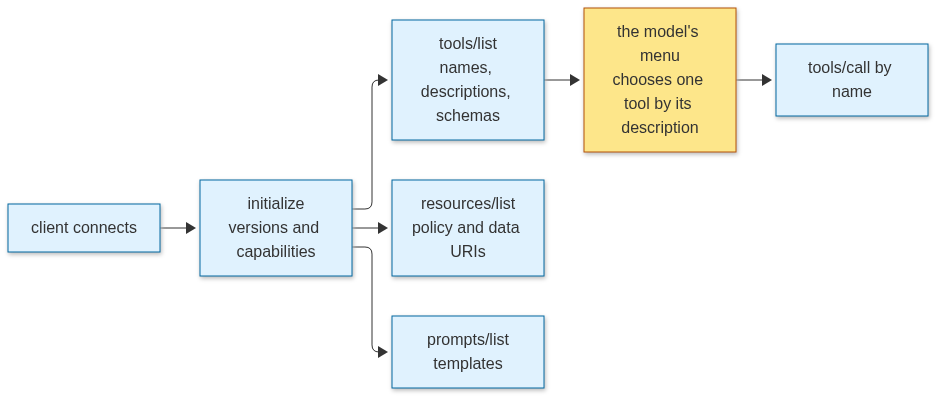

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  C["client connects"] --> I["initialize<br/>versions and capabilities"]
  I --> LT["tools/list<br/>names, descriptions, schemas"]
  I --> LR["resources/list<br/>policy and data URIs"]
  I --> LP["prompts/list<br/>templates"]
  LT --> M["the model's menu<br/>chooses one tool by its description"]
  M --> CALL["tools/call by name"]
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M model
  class C,I,LT,LR,LP,CALL code
""")

## Step by step

**Step 1 · a server with two tools (no call).** This lesson's server has two tools, so a model has a real choice to make: the order lookup and
a policy text. The folder is created first; the server file is written in the next cell, and the client starts it over stdio, as in lesson 22.

In [2]:
from pathlib import Path

Path("../../../data/lg23").mkdir(parents=True, exist_ok=True)  # this lesson's run-time folder

Next, the server file. `%%writefile` is a notebook magic: the cell saves its text to `desk_server.py` instead of running it. The server
has two tools, each marked with `@mcp.tool()`, and ends with `mcp.run()` so that a client can start it.

In [3]:
%%writefile ../../../data/lg23/desk_server.py
"""Two Brightside tools for the discovery lesson (23). The client starts this file over stdio."""
import json
from pathlib import Path

from mcp.server import MCPServer

GOLDEN = json.loads((Path(__file__).resolve().parents[1] / "support_eval.json").read_text())
ORDERS = GOLDEN["world"]["orders"]
POLICY = GOLDEN["policy"]

mcp = MCPServer("brightside-desk", log_level="WARNING")


@mcp.tool()
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status, days late and total. Use it when the customer gives an order number."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})


@mcp.tool()
def policy_text(topic: str) -> str:
    """Return the desk's written policy on returns, refunds or delivery."""
    return POLICY


if __name__ == "__main__":
    mcp.run()

Overwriting ../../../data/lg23/desk_server.py


The client finds the server file by this path. Printing its name checks that the path is right.

In [4]:
SERVER = Path("../../../data/lg23/desk_server.py").resolve()
print("server:", SERVER.name)

server: desk_server.py


**Step 2 · discover what the server offers (no model call).** The client connects, asks for the three lists, and prints them. Nothing here is
written into the client: the names, schemas and descriptions all come from the server. This server has no resources and no prompts,
so only the two tool lines print, and the prompts line shows an empty list.

In [5]:
import sys
from mcp import Client, StdioServerParameters

STDIO = StdioServerParameters(command=sys.executable, args=[str(SERVER)])


async def discover() -> dict:
    async with Client(STDIO) as client:
        tools = (await client.list_tools()).tools
        resources = (await client.list_resources()).resources
        prompts = (await client.list_prompts()).prompts
    return {"tools": tools, "resources": resources, "prompts": prompts}


found = await discover()
for tool in found["tools"]:
    print("tool:", tool.name, "| takes:", list(tool.input_schema["properties"]), "| says:", tool.description)
for resource in found["resources"]:
    print("resource:", resource.uri, "|", resource.name)
print("prompts:", [p.name for p in found["prompts"]])

tool: lookup_order | takes: ['order_id'] | says: Look up one customer order: its status, days late and total. Use it when the customer gives an order number.
tool: policy_text | takes: ['topic'] | says: Return the desk's written policy on returns, refunds or delivery.
prompts: []


**Step 3 · the model's menu (no call).** The model does not see the server. It sees the tools the client gives it, each with its name, description
and schema. This step builds that menu from the discovered tools, and prints what the model would read.

In [6]:
def menu(tools) -> list[dict]:
    return [{"name": t.name, "description": t.description, "parameters": t.input_schema} for t in tools]


for entry in menu(found["tools"]):
    print(entry["name"], "→", entry["description"])

lookup_order → Look up one customer order: its status, days late and total. Use it when the customer gives an order number.
policy_text → Return the desk's written policy on returns, refunds or delivery.


**Step 4 · what the model reads when it chooses (1 model call per menu).** The same question goes to the model twice: once with the descriptions the
server published, and once with the two descriptions swapped. The swapped menu is only used to ask the model; it is never sent to the server.
The result shows what the model weighs. In the recorded run it still chose `lookup_order` after the swap, so the name and the question count as well as
the description. A description shapes the choice; it is not the only thing that does.

In [7]:
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("23_mcp-discovery")

from langchain_core.messages import HumanMessage
from llm_setup import get_llm  # course helper: the course's model setup, the same for every lesson

llm = get_llm()
QUESTION = "Order 1003 never arrived. What is its status?"


def which_tool(tools_menu: list[dict]) -> str:
    bound = llm.bind_tools([{"name": m["name"], "description": m["description"], "parameters": m["parameters"]}
                            for m in tools_menu])
    reply = bound.invoke([HumanMessage(content=QUESTION)])
    return reply.tool_calls[0]["name"] if reply.tool_calls else "no tool"


print("with the server's description:", which_tool(menu(found["tools"])))
swapped = [dict(m, description="Returns the desk's refund and returns policy text.") if m["name"] == "lookup_order"
           else dict(m, description="Looks up one customer order's status and days late.") for m in menu(found["tools"])]
print("with the two descriptions swapped:", which_tool(swapped))
llm_replay.stop()  # the last model call of this lesson

LLM mode: replay (23_mcp-discovery.yaml)


Gemini on Vertex AI · API key loaded: True


with the server's description: lookup_order
with the two descriptions swapped: lookup_order


**Step 5 · call a discovered tool (no model call).** The client calls the tool by the name it discovered, with arguments that match the schema it
discovered. The server checks the call, runs the tool, and returns the result.

In [8]:
async def call_discovered(name: str, args: dict):
    async with Client(STDIO) as client:
        result = await client.call_tool(name, args)
        return result.content[0].text


print(await call_discovered("lookup_order", {"order_id": "1003"}))

{
  "status": "lost",
  "days_late": 9,
  "total": 89.5
}


## At work
- Teams let clients discover the server's tools on connect, so a new tool reaches every client without a release → lesson 24 (registry and gateway).
- Descriptions are read by the model, so they are reviewed like prompts. A description that promises too much makes the model call the tool
  when it should not → lesson 34 (security and guardrails).
- Discovery is a list the server publishes. The client still checks each tool against its own allow-list before it gives the tool to the model.

## What just happened
- The server offered two tools, `lookup_order` and `policy_text`, and no resources or prompts. The client found them with no list typed in.
- The model chose `lookup_order` both with the server's description and with the swapped one, so the description alone did not decide it.
- Calling `lookup_order` with order 1003 returned status `lost`, 9 days late, total 89.5.

## Common mistakes
1. **A tool list typed into the client.** It drifts from the server. Discover on connect.
2. **A vague description.** The model picks from the name, the description and the question together. Test the menu with real questions, as Step 4 does.
3. **Giving the model every discovered tool.** Discovery shows what exists; the allow-list decides what the model may use.

## Try it
Write `tool_names(tools)` that returns the sorted names of the discovered tools. Test it on `found["tools"]`. No model call is needed.

In [9]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [10]:
def tool_names(tools) -> list[str]:
    return sorted(t.name for t in tools)


print(tool_names(found["tools"]))  # ['lookup_order', 'policy_text']

['lookup_order', 'policy_text']


## Key terms
- **tools/list** — the MCP request that asks a server for its tools, with names, descriptions and schemas.
- **resources/list** — the MCP request that asks a server for the data it publishes, as URIs.
- **prompts/list** — the MCP request that asks a server for its prompt templates.
- **schema** — the JSON description of a tool's arguments; the client sends arguments that match it.
- **tool description** — the text the model reads to decide whether to pick a tool.
- **allow-list** — the client's own list of the tools it may give the model, whatever the server offers.
- **stdio** — a transport in which the client starts the server as a child process and talks to it over standard input and output.
- **tools/call** — the MCP request that runs one tool by name with arguments.

## Recap
- A client discovers the server's tools, resources and prompts on connect; nothing is typed into the client.
- The model chooses a tool from its name, its description and the question. The description is part of the contract, and it is not the only input.
- The client calls a tool by the name and schema it discovered.

**Interview:** "How does a client keep working when the server adds a tool?" Strong answer: "It lists the server's tools on connect, so the new tool is
in the list. The model chooses from the descriptions, which I review like prompts, and the client's allow-list decides which tools the model may use."